# Praktikum 1 - Pra Pengolahan Data: Ekstraksi Fitur (Data Terstruktur)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 03:** Ekstraksi Fitur

### Tujuan Praktikum:
1. Memuat dataset Titanic dan melakukan inspeksi data yang hilang (*missing values*).
2. Melakukan data imputasi pada kolom `Age`, `Cabin`, dan `Embarked`.
3. Mengekstraksi fitur-fitur baru: `FamilySize`, `Title`, `AgeBin`, `CabinDeck`, dan `FarePerPerson`.
4. Memvisualisasikan hubungan antara fitur hasil ekstraksi dengan tingkat keselamatan (*Survival Rate*).

## Langkah 1 - Load Data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = r'..\Dataset\Titanic-Dataset.csv'

df = pd.read_csv(data_path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Langkah 2 - Pengecekan Data dan Missing Values

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Langkah 3 - Imputasi Missing Values
- `Age`: diimputasi menggunakan nilai mean (rata-rata).
- `Cabin`: diimputasi dengan string `'DECK'`.
- `Embarked`: diimputasi dengan modus (nilai terbanyak).

In [4]:
# Imputasi Age dengan mean
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Imputasi Cabin dengan 'DECK'
df['Cabin'] = df['Cabin'].fillna('DECK')

# Imputasi Embarked dengan modus
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

## Langkah 4 - Validasi Hasil Imputasi

In [5]:
print('Jumlah missing value setelah imputasi:')
print(df.isnull().sum())
df[['Age', 'Cabin', 'Embarked']].head()

Jumlah missing value setelah imputasi:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


,Age,Cabin,Embarked
0,22.0,DECK,S
1,38.0,C85,C
2,26.0,DECK,S
3,35.0,C123,S
4,35.0,DECK,S


## Langkah 5 - Ekstraksi Fitur
Mengekstraksi 5 fitur baru dari data mentah:
1. `FamilySize`: Total keluarga = `SibSp` + `Parch` + 1
2. `Title`: Gelar kehormatan/sapaan dari nama penumpang
3. `AgeBin`: Pengelompokan usia ke dalam kategori (*Child, Teen, YoungAdult, Adult, Senior*)
4. `CabinDeck`: Inisial dek dari kolom kabin
5. `FarePerPerson`: Biaya tiket dibagi jumlah anggota keluarga

In [6]:
# 1. FamilySize
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# 2. Title
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)
title_mapping = {
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs',
    'Lady': 'Rare', 'Countess': 'Rare', 'Capt': 'Rare', 'Col': 'Rare',
    'Don': 'Rare', 'Dr': 'Rare', 'Major': 'Rare', 'Rev': 'Rare',
    'Sir': 'Rare', 'Jonkheer': 'Rare', 'Dona': 'Rare'
}
df['Title'] = df['Title'].replace(title_mapping)

# 3. AgeBin
df['AgeBin'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100],
                      labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])

# 4. CabinDeck
df['CabinDeck'] = df['Cabin'].astype(str).str[0]

# 5. FarePerPerson
df['FarePerPerson'] = df['Fare'] / df['FamilySize']

print('Hasil Ekstraksi Fitur:')
df[['Name', 'Title', 'Age', 'AgeBin', 'FamilySize', 'Cabin', 'CabinDeck', 'FarePerPerson']].head()

Hasil Ekstraksi Fitur:


,Name,Title,Age,AgeBin,FamilySize,Cabin,CabinDeck,FarePerPerson
0,"Braund, Mr. Owen Harris",Mr,22.0,YoungAdult,2,DECK,D,3.62500
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.0,Adult,2,C85,C,35.64165
2,"Heikkinen, Miss. Laina",Miss,26.0,YoungAdult,1,DECK,D,7.92500
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.0,YoungAdult,2,C123,C,26.55000
4,"Allen, Mr. William Henry",Mr,35.0,YoungAdult,1,DECK,D,8.05000


## Langkah 6 - Visualisasi Hasil Ekstraksi Fitur

C:\Users\luvma\AppData\Local\Temp\ipykernel_23960\1741246732.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='FamilySize', y='Survived', data=df, ax=axes[0, 0], palette='Blues_d')
C:\Users\luvma\AppData\Local\Temp\ipykernel_23960\1741246732.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Title', y='Survived', data=df, order=order_title, ax=axes[0, 1], palette='Purples_d')
C:\Users\luvma\AppData\Local\Temp\ipykernel_23960\1741246732.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='AgeBin', y='Survived', data=df, order=['Ch

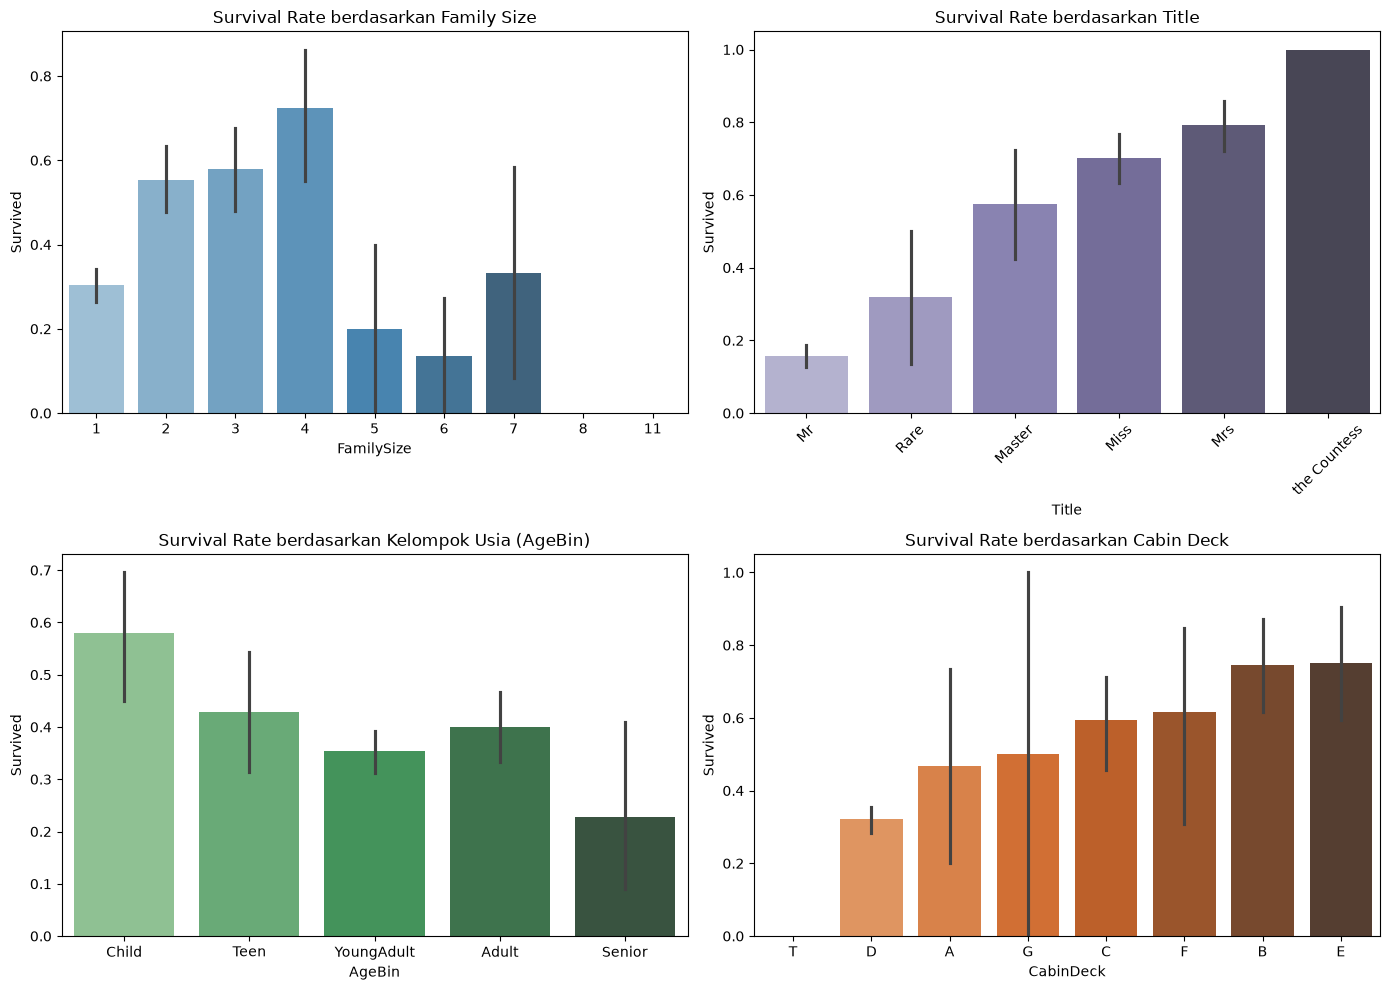

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Survival Rate vs FamilySize
sns.barplot(x='FamilySize', y='Survived', data=df, ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Survival Rate berdasarkan Family Size')

# Survival Rate vs Title
order_title = df.groupby('Title')['Survived'].mean().sort_values().index
sns.barplot(x='Title', y='Survived', data=df, order=order_title, ax=axes[0, 1], palette='Purples_d')
axes[0, 1].set_title('Survival Rate berdasarkan Title')
axes[0, 1].tick_params(axis='x', rotation=45)

# Survival Rate vs AgeBin
sns.barplot(x='AgeBin', y='Survived', data=df, order=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'], ax=axes[1, 0], palette='Greens_d')
axes[1, 0].set_title('Survival Rate berdasarkan Kelompok Usia (AgeBin)')

# Survival Rate vs CabinDeck
order_deck = df.groupby('CabinDeck')['Survived'].mean().sort_values().index
sns.barplot(x='CabinDeck', y='Survived', data=df, order=order_deck, ax=axes[1, 1], palette='Oranges_d')
axes[1, 1].set_title('Survival Rate berdasarkan Cabin Deck')

plt.tight_layout()
plt.show()